In [1]:
import numpy as np
import matplotlib.pyplot as plt

from notebooks.analysis import final_positions

In [2]:
%load_ext autoreload
%autoreload 2
from src.markov_chains import generate_paths

First I will try a simple two state markov chain

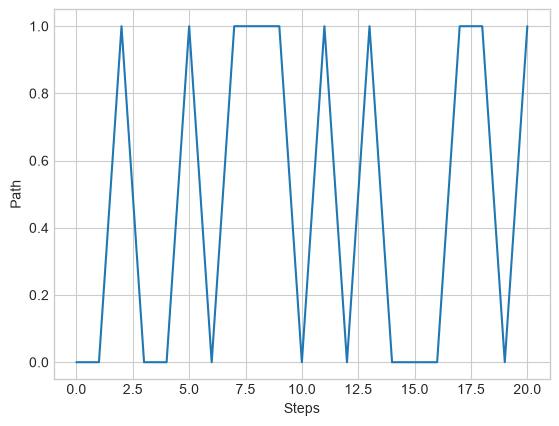

In [3]:
States = [0, 1]
Transition_matrix = np.array([[0.2,0.8], [0.6,0.4]])

steps = 20
current_state = 0
path = np.array([current_state])

for i in range(steps):
    current_state = np.random.choice(States, p=Transition_matrix[current_state])
    path = np.append(path, current_state)

plt.plot(path)
plt.xlabel("Steps")
plt.ylabel("Path")
plt.show()

I will use this same model and calculate the probabilty of the system going from 0 to 1 over 3 steps, using matrix multiplication

In [74]:
transition_matrix = np.array([[0,0.3,0.7],[0.4,0,0.6],[0.5,0.5,0]])
P3 = np.linalg.matrix_power(transition_matrix, 3)

start_distribution = np.array([0.2,0.4,0.4])
print(np.matmul(start_distribution, P3))
print(P3)

[0.3232 0.2922 0.3846]
[[0.23  0.231 0.539]
 [0.308 0.23  0.462]
 [0.385 0.385 0.23 ]]


In [25]:
states = [0,1,2]
transition_matrix = np.array([[0,0.3,0.7],[0.4,0,0.6],[0.5,0.5,0]])
start_distribution = np.array([0.2,0.4,0.4])
n_steps = 20

paths = generate_paths(10000, n_steps, states, transition_matrix, start_distribution)
final_positions = paths[:,-1]

ratio0 = np.sum(final_positions == 0)/len(final_positions)
ratio1 = np.sum(final_positions == 1)/len(final_positions)
ratio2 = np.sum(final_positions == 2)/len(final_positions)

row_vector_of_probabilities = np.matmul(start_distribution, np.linalg.matrix_power(transition_matrix, n_steps))

print(row_vector_of_probabilities)
print(ratio0, ratio1, ratio2)


[0.31389876 0.29147617 0.39462507]
0.3097 0.287 0.4033


[0.31389876 0.29147617 0.39462507]
0.3185 0.287 0.3945


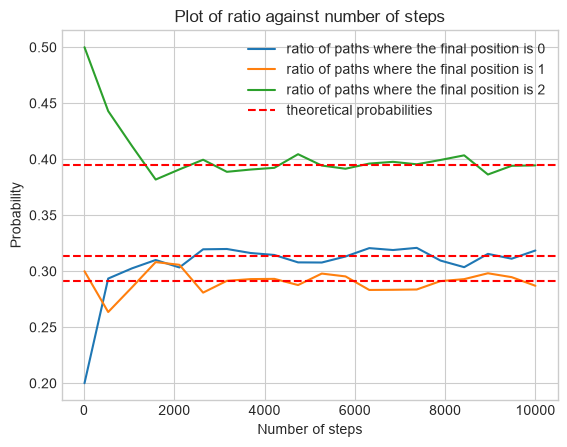

In [29]:
states = [0,1,2]
transition_matrix = np.array([[0,0.3,0.7],[0.4,0,0.6],[0.5,0.5,0]])
start_distribution = np.array([0.2,0.4,0.4])
n_steps = 20

n_paths = np.linspace(10,10000, 20).astype(int)
ratios0 = []
ratios1 = []
ratios2 = []

for i in n_paths:
    paths = generate_paths(i, n_steps, states, transition_matrix, start_distribution)
    final_positions = paths[:,-1]

    ratio0 = np.sum(final_positions == 0)/len(final_positions)
    ratio1 = np.sum(final_positions == 1)/len(final_positions)
    ratio2 = np.sum(final_positions == 2)/len(final_positions)
    ratios0.append(ratio0)
    ratios1.append(ratio1)
    ratios2.append(ratio2)

row_vector_of_probabilities = np.matmul(start_distribution, np.linalg.matrix_power(transition_matrix, n_steps))

print(row_vector_of_probabilities)
print(ratio0, ratio1, ratio2)

plt.plot(n_paths, ratios0, label = "ratio of paths where the final position is 0")
plt.plot(n_paths, ratios1, label = "ratio of paths where the final position is 1")
plt.plot(n_paths, ratios2, label = "ratio of paths where the final position is 2")
plt.axhline(y=row_vector_of_probabilities[0], linestyle='--', color='r', label = "theoretical probabilities")
plt.axhline(y=row_vector_of_probabilities[1], linestyle='--', color='r')
plt.axhline(y=row_vector_of_probabilities[2], linestyle='--', color='r')
plt.title("Plot of ratio against number of steps")
plt.xlabel("Number of steps")
plt.ylabel("Probability")
plt.legend()




now lets try implement gamblers ruin

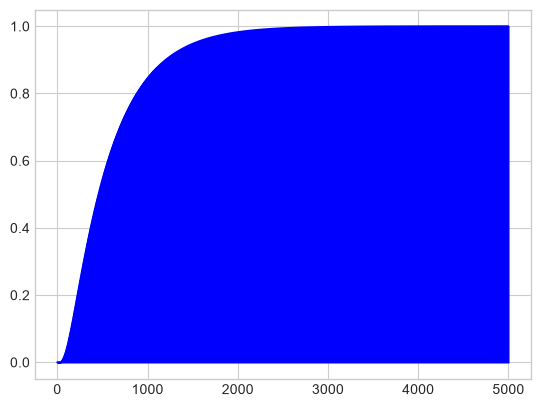

In [71]:
p=0.51
m=50
a=20
n_steps= np.arange(1,5000)

P =np.zeros((m+1,m+1))
P[0,0] = 1
P[m,m] = 1
for i in range(1, m):
    P[i,i-1] = 1-p
    P[i,i+1] = p

cdf = []
for i in n_steps:
    row_vector_of_probabilities = np.linalg.matrix_power(P, i)[a]
    probability_of_ruin = row_vector_of_probabilities[0] + row_vector_of_probabilities[-1]
    cdf.append(probability_of_ruin)

plt.plot(n_steps, cdf, color = "blue")
plt.fill_between(x=n_steps, y1=cdf, y2=0, color = "blue")
